# Early Disease Prediction Using Machine Learning on Health Data

## 1. Import Required Libraries

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import joblib
import os

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Load Dataset

In [18]:
# Column names for the Pima Indians Diabetes Dataset
columns = [
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age',
    'Outcome'
]

# Load the raw dataset
df = pd.read_csv('../dataset/diabetes.csv', header=None, names=columns)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 3. Dataset Inspection

In [19]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [20]:
print("Statistical Summary:")
df.describe()

Statistical Summary:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [21]:
print("Number of missing values:")
print(df.isnull().sum())

Number of missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [22]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [23]:
print("Unique values in Outcome:")
print(df['Outcome'].value_counts())

print("\nOutcome distribution:")
print(df['Outcome'].value_counts(normalize=True) * 100)

Unique values in Outcome:
Outcome
0    500
1    268
Name: count, dtype: int64

Outcome distribution:
Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64


## 4. Data Cleaning

In [24]:
# In the original Pima dataset, zero is used to represent
# missing/invalid measurements in these medical features.

zero_columns = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

print("Zero values before cleaning:")

for column in zero_columns:
    print(f"{column}: {(df[column] == 0).sum()}")

Zero values before cleaning:
Glucose: 5
BloodPressure: 35
SkinThickness: 227
Insulin: 374
BMI: 11


In [25]:
# Replace invalid zero values with NaN.
# We do NOT use Outcome to determine replacement values.

df[zero_columns] = df[zero_columns].replace(0, np.nan)

print("Missing values after converting invalid zeros:")
print(df.isnull().sum())

Missing values after converting invalid zeros:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [26]:
# Check for negative values

numeric_columns = df.columns

negative_values = (df[numeric_columns] < 0).sum()

print("Negative values:")
print(negative_values)

Negative values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [27]:
# Save the cleaned dataset for reference

os.makedirs('../cleaned_dataset', exist_ok=True)

df.to_csv(
    '../cleaned_dataset/cleaned_diabetes.csv',
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


## 5. Exploratory Data Analysis

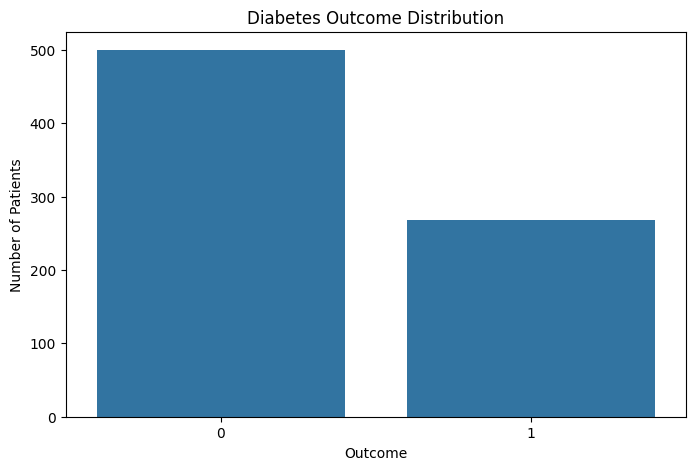

In [28]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Outcome')

plt.title('Diabetes Outcome Distribution')
plt.xlabel('Outcome')
plt.ylabel('Number of Patients')

plt.show()

<Figure size 1000x600 with 0 Axes>

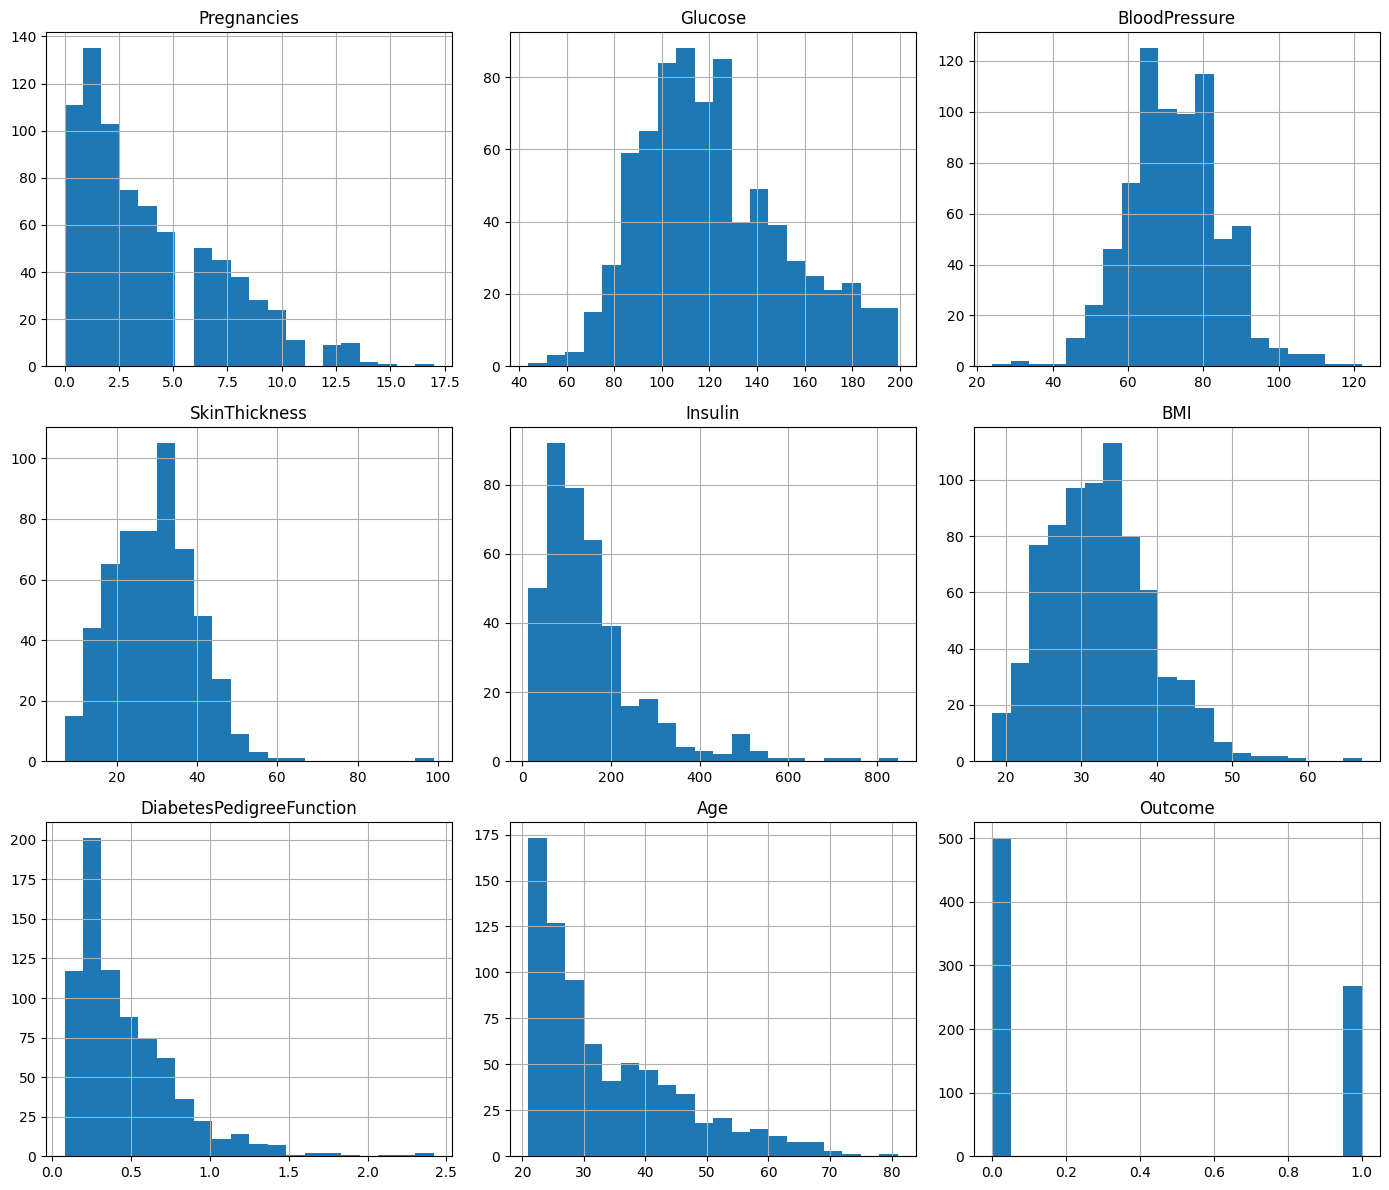

In [29]:
plt.figure(figsize=(10, 6))

df.hist(
    figsize=(14, 12),
    bins=20
)

plt.tight_layout()
plt.show()

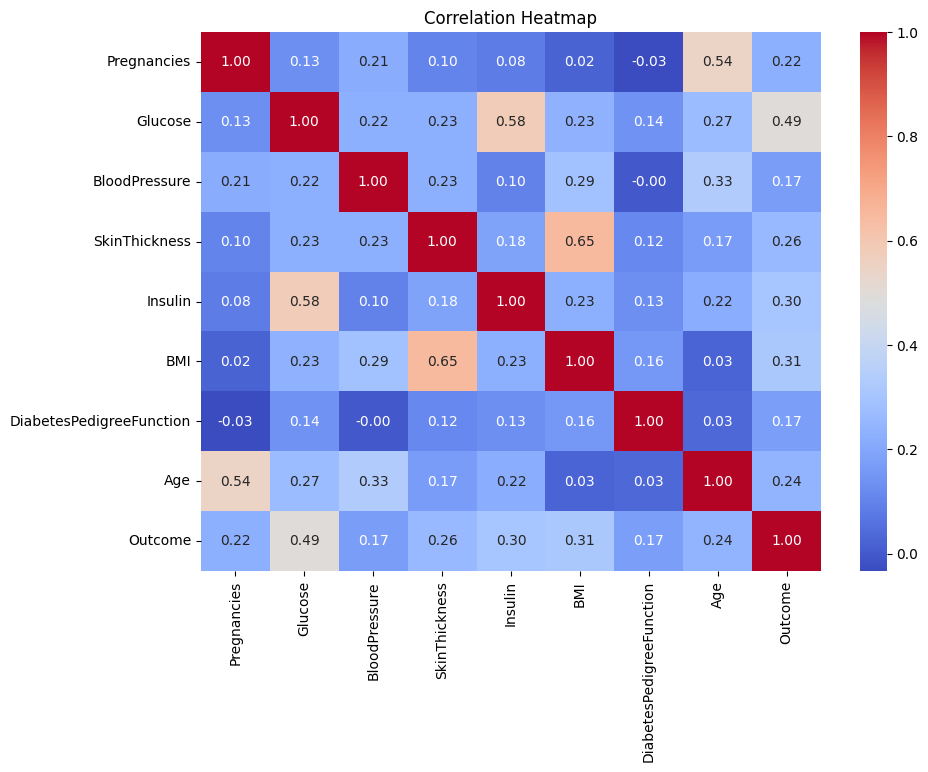

In [30]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

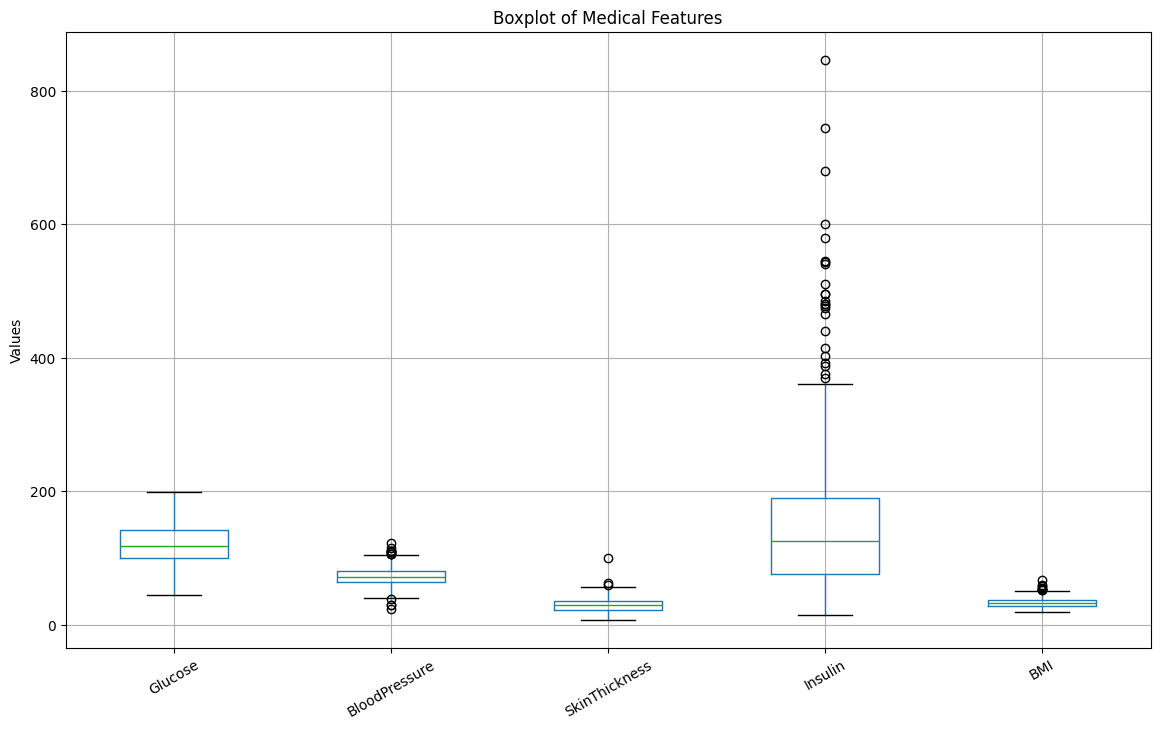

In [31]:
plt.figure(figsize=(14, 8))

df[zero_columns].boxplot()

plt.title('Boxplot of Medical Features')
plt.ylabel('Values')

plt.xticks(rotation=30)

plt.show()

## 6. Data Preprocessing

In [33]:
# Separate features and target

X = df.drop('Outcome', axis=1)
y = df['Outcome']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (768, 8)
Target shape: (768,)


In [34]:
# Split BEFORE fitting the imputer.
# This prevents information from the test set from entering training.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 614
Testing samples: 154


In [35]:
# Median imputation
# IMPORTANT:
# The median is learned ONLY from X_train.

imputer = SimpleImputer(strategy='median')

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

print("Training data after imputation:", X_train_imputed.shape)
print("Testing data after imputation:", X_test_imputed.shape)

Training data after imputation: (614, 8)
Testing data after imputation: (154, 8)


In [36]:
# Standardization for models that benefit from feature scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


### 7.1 Logistic Regression

In [38]:
logistic_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

logistic_pred = logistic_model.predict(X_test_scaled)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


### 7.2 Decision Tree

In [39]:
decision_tree_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

decision_tree_model.fit(
    X_train_imputed,
    y_train
)

decision_tree_pred = decision_tree_model.predict(
    X_test_imputed
)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


### 7.3 Random Forest

In [40]:
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest_model.fit(
    X_train_imputed,
    y_train
)

random_forest_pred = random_forest_model.predict(
    X_test_imputed
)

print("Random Forest trained successfully!")

Random Forest trained successfully!


### 7.4 K-Nearest Neighbors

In [41]:
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(
    X_train_scaled,
    y_train
)

knn_pred = knn_model.predict(
    X_test_scaled
)

print("KNN trained successfully!")

KNN trained successfully!


### 7.5 Support Vector Machine

In [42]:
svm_model = SVC(
    kernel='rbf',
    probability=True,
    random_state=42
)

svm_model.fit(
    X_train_scaled,
    y_train
)

svm_pred = svm_model.predict(
    X_test_scaled
)

print("SVM trained successfully!")

SVM trained successfully!


## 8. Model Evaluation

In [43]:
models = {
    'Logistic Regression': logistic_pred,
    'Decision Tree': decision_tree_pred,
    'Random Forest': random_forest_pred,
    'KNN': knn_pred,
    'SVM': svm_pred
}

results = []

for model_name, predictions in models.items():

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, zero_division=0)
    recall = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)

    results.append({
        'Model': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

results_df = pd.DataFrame(results)

results_df.sort_values(
    by='F1-Score',
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.759740,0.639344,0.722222,0.678261
1,Random Forest,0.766234,0.695652,0.592593,0.640000
2,KNN,0.753247,0.660000,0.611111,0.634615
3,SVM,0.740260,0.652174,0.555556,0.600000
4,Logistic Regression,0.707792,0.600000,0.500000,0.545455


In [44]:
# Display results as percentages

results_percentage = results_df.copy()

for column in ['Accuracy', 'Precision', 'Recall', 'F1-Score']:
    results_percentage[column] = (
        results_percentage[column] * 100
    ).round(2)

results_percentage.sort_values(
    by='F1-Score',
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,75.97,63.93,72.22,67.83
1,Random Forest,76.62,69.57,59.26,64.00
2,KNN,75.32,66.00,61.11,63.46
3,SVM,74.03,65.22,55.56,60.00
4,Logistic Regression,70.78,60.00,50.00,54.55


### Classification Reports

In [45]:
for model_name, predictions in models.items():

    print("=" * 60)
    print(model_name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            predictions,
            target_names=['No Diabetes', 'Diabetes'],
            zero_division=0
        )
    )

Logistic Regression
              precision    recall  f1-score   support

 No Diabetes       0.75      0.82      0.78       100
    Diabetes       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154

Decision Tree
              precision    recall  f1-score   support

 No Diabetes       0.84      0.78      0.81       100
    Diabetes       0.64      0.72      0.68        54

    accuracy                           0.76       154
   macro avg       0.74      0.75      0.74       154
weighted avg       0.77      0.76      0.76       154

Random Forest
              precision    recall  f1-score   support

 No Diabetes       0.80      0.86      0.83       100
    Diabetes       0.70      0.59      0.64        54

    accuracy                           0.77       154
   macro avg       0.75      0.73      0.73       154
weighted avg       0.76   

## 9. Confusion Matrices

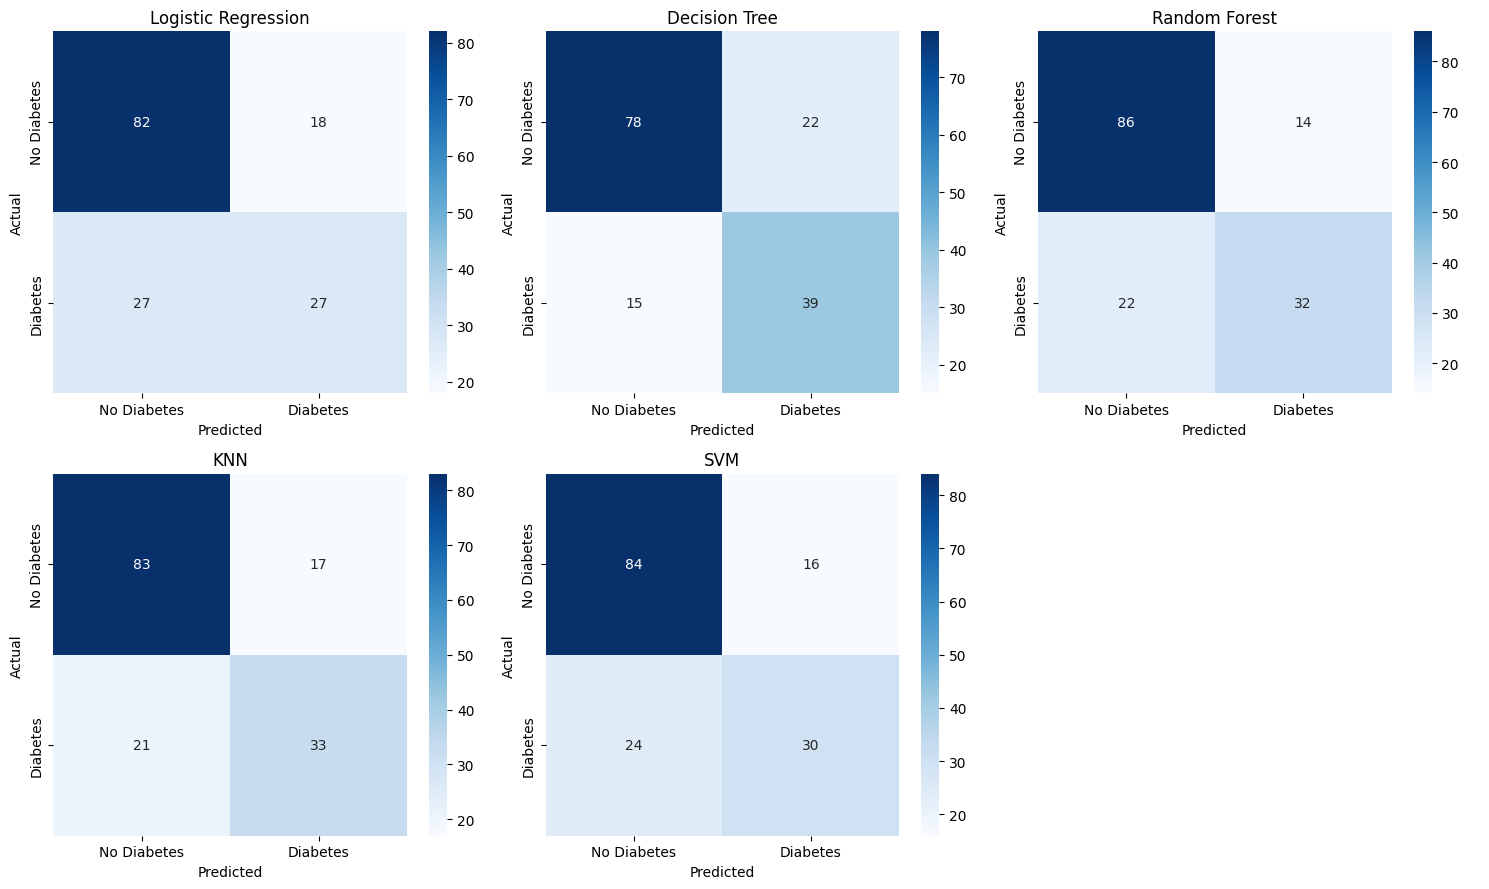

In [46]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 9)
)

axes = axes.ravel()

for i, (model_name, predictions) in enumerate(models.items()):

    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=axes[i],
        xticklabels=['No Diabetes', 'Diabetes'],
        yticklabels=['No Diabetes', 'Diabetes']
    )

    axes[i].set_title(model_name)
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

# Hide unused sixth subplot
axes[-1].axis('off')

plt.tight_layout()
plt.show()

## 10. Model Comparison

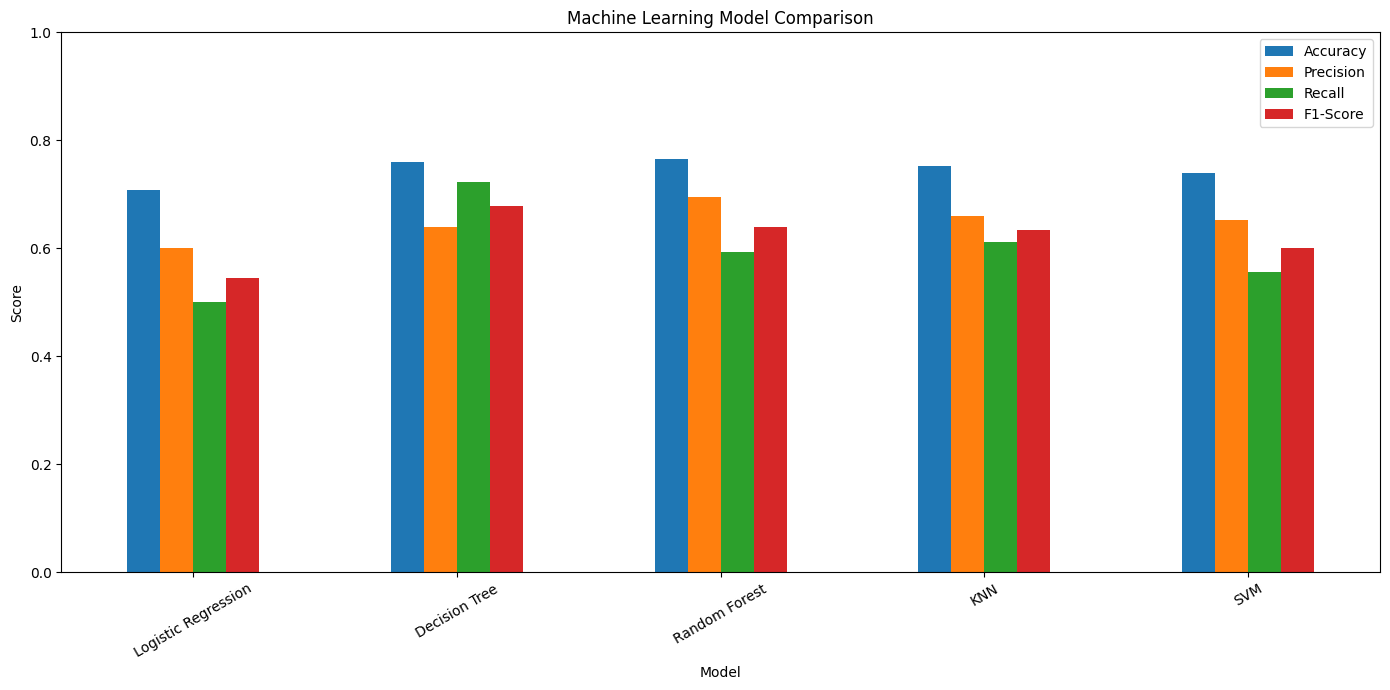

In [47]:
comparison_plot = results_df.set_index('Model')

comparison_plot[
    ['Accuracy', 'Precision', 'Recall', 'F1-Score']
].plot(
    kind='bar',
    figsize=(14, 7)
)

plt.title('Machine Learning Model Comparison')
plt.ylabel('Score')
plt.xlabel('Model')

plt.ylim(0, 1)

plt.xticks(rotation=30)

plt.legend()

plt.tight_layout()
plt.show()

In [49]:
best_model_row = results_df.loc[
    results_df['F1-Score'].idxmax()
]

print("Model with the highest F1-score:")
print(best_model_row['Model'])

print(
    "F1-score:",
    round(best_model_row['F1-Score'], 4)
)

Model with the highest F1-score:
Decision Tree
F1-score: 0.6783


## 11. Prediction on New Patient

## 11. Prediction on New Patient

In [51]:
# Example patient

new_patient = pd.DataFrame({
    'Pregnancies': [2],
    'Glucose': [120],
    'BloodPressure': [70],
    'SkinThickness': [25],
    'Insulin': [80],
    'BMI': [28.5],
    'DiabetesPedigreeFunction': [0.35],
    'Age': [35]
})

new_patient

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,2,120,70,25,80,28.5,0.35,35


In [52]:
# Apply the SAME imputer that was fitted on the training data

new_patient_imputed = imputer.transform(new_patient)

prediction = random_forest_model.predict(
    new_patient_imputed
)[0]

probabilities = random_forest_model.predict_proba(
    new_patient_imputed
)[0]

no_diabetes_probability = probabilities[0]
diabetes_probability = probabilities[1]

print(
    "Prediction:",
    "Diabetes" if prediction == 1 else "No Diabetes"
)

print(
    f"No Diabetes Probability: {no_diabetes_probability * 100:.2f}%"
)

print(
    f"Diabetes Probability: {diabetes_probability * 100:.2f}%"
)

Prediction: No Diabetes
No Diabetes Probability: 66.00%
Diabetes Probability: 34.00%


## 12. Save Final Random Forest Model

In [54]:
os.makedirs('../models', exist_ok=True)

# Save the Random Forest model
joblib.dump(
    random_forest_model,
    '../models/random_forest_model.pkl'
)

# Save the imputer separately
joblib.dump(
    imputer,
    '../models/diabetes_imputer.pkl'
)

print("Random Forest model saved successfully!")
print("Imputer saved successfully!")

Random Forest model saved successfully!
Imputer saved successfully!


In [55]:
print("Saved model files:")

print(
    os.path.exists(
        '../models/random_forest_model.pkl'
    )
)

print(
    os.path.exists(
        '../models/diabetes_imputer.pkl'
    )
)

Saved model files:
True
True


## 13. Conclusion

The Pima Indians Diabetes Dataset was analyzed and preprocessed
using leakage-safe techniques.

Invalid zero values in selected medical features were treated as
missing values.

The dataset was divided into training and testing sets before
fitting the median imputer.

Multiple machine learning models were trained and evaluated using
accuracy, precision, recall and F1-score.

The Random Forest model was also saved for use in the application.
